In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


I started by importing the libraries needed to explore the Alexa reviews dataset, prepare the text, and build classification models. I also imported evaluation tools to help me measure how accurately the models predict positive and negative feedback

In [2]:
#Load dataset
#Load the Amazon Alexa reviews
df = pd.read_csv("amazon_alexa.tsv", sep="\t")

#Remove extra spaces from column names
df.columns = df.columns.str.strip()

#Preview the data
print("Dataset Shape:", df.shape)
display(df.head())

#Review the column information
df.info()

Dataset Shape: (3150, 5)


,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,5,31-Jul-18,Charcoal Fabric,Music,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   rating            3150 non-null   int64 
 1   date              3150 non-null   object
 2   variation         3150 non-null   object
 3   verified_reviews  3149 non-null   object
 4   feedback          3150 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 123.2+ KB


I loaded the Amazon Alexa reviews dataset and looked at the first five records to see what information was included. I also checked the number of rows, columns, and data types. For this assignment, I'll be focusing on the review text and feedback columns since the goal is to predict whether a review is positive or negative.

In [3]:
#EDA
#Descriptive statistics
display(df.describe(include="all").T)

#Check missing values
print("Missing Values:")
print(df.isnull().sum())

#Check duplicates
print("\nDuplicate Records:")
print(df.duplicated().sum())

#Check feedback distribution
print("\nFeedback Counts:")
print(df["feedback"].value_counts(dropna=False))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rating,3150.0,NaN,NaN,NaN,4.463175,1.068506,1.0,4.0,5.0,5.0,5.0
date,3150,77,30-Jul-18,1603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
variation,3150,16,Black Dot,516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
verified_reviews,3149,2300,,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
feedback,3150.0,NaN,NaN,NaN,0.918413,0.273778,0.0,1.0,1.0,1.0,1.0


Missing Values:
rating              0
date                0
variation           0
verified_reviews    1
feedback            0
dtype: int64

Duplicate Records:
715

Feedback Counts:
feedback
1    2893
0     257
Name: count, dtype: int64


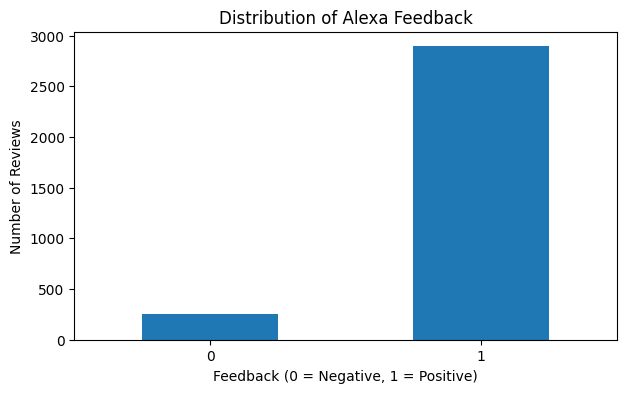

In [4]:
#Visualize positive and negative feedback
df["feedback"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribution of Alexa Feedback")
plt.xlabel("Feedback (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

I performed EDA to better understand the dataset before training the model. I also created a bar chart to compare the two feedback categories. This is important because if there are significantly more positive reviews than negative ones, it could affect how well the model learns to recognize negative feedback.

In [5]:
#Clean the data
#Keep only the columns needed
df_clean = df[["verified_reviews", "feedback"]].copy()

#Convert the review text to strings
df_clean["verified_reviews"] = (
    df_clean["verified_reviews"]
    .fillna("")
    .astype(str)
    .str.strip()
)

#Convert feedback to numerical values
df_clean["feedback"] = pd.to_numeric(
    df_clean["feedback"],
    errors="coerce"
)

#Remove empty reviews and missing feedback
df_clean = df_clean[
    (df_clean["verified_reviews"] != "") &
    (df_clean["feedback"].isin([0, 1]))
].copy()

#Remove duplicate review and feedback pairs
df_clean = df_clean.drop_duplicates()

#Confirm the cleaned dataset
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nFeedback Distribution:")
print(df_clean["feedback"].value_counts())

display(df_clean.head())

Cleaned Dataset Shape: (2299, 2)

Feedback Distribution:
feedback
1    2094
0     205
Name: count, dtype: int64


,verified_reviews,feedback
0,Love my Echo!,1
1,Loved it!,1
2,"Sometimes while playing a game, you can answer...",1
3,I have had a lot of fun with this thing. My 4 ...,1
4,Music,1


I cleaned the dataset by keeping only the review text and feedback columns. I removed empty reviews, missing feedback values, and duplicate review records. I also made sure the feedback labels were numerical, with 1 representing positive feedback and 0 representing negative feedback. This helps prepare the data so the model can learn from the review text without having unnecessary or missing information.

In [6]:
#Split into training and testing data
#Separate the review text and feedback labels
X = df_clean["verified_reviews"]
y = df_clean["feedback"].astype(int)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Reviews:", len(X_train))
print("Testing Reviews:", len(X_test))

print("\nTraining Feedback Counts:")
print(y_train.value_counts())

Training Reviews: 1839
Testing Reviews: 460

Training Feedback Counts:
feedback
1    1675
0     164
Name: count, dtype: int64


I separated the review text from the feedback labels and split the dataset into 80% training data and 20% testing data. I also used stratify to keep the proportion of positive and negative reviews similar in both sets. This should be helpful since the dataset may have more positive reviews than negative ones.

In [7]:
#Build Logistic Regression Model
#TF-IDF and Logistic Regression
#Create the text classification pipeline
logistic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=3000,
        ngram_range=(1, 2)
    )),
    ("logistic", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

#Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

#Predict feedback on the test set
logistic_predictions = logistic_model.predict(X_test)

Logistic Regression model trained successfully.


In [8]:
#Preview predictions
results = pd.DataFrame({
    "Review": X_test.values,
    "Actual Feedback": y_test.values,
    "Predicted Feedback": logistic_predictions
})

display(results.head(10))

,Review,Actual Feedback,Predicted Feedback
0,We have five of them. Need I say more?,1,1
1,I love searching the Alexa skill shop on the a...,1,1
2,I switched to google. The amazon helper is mor...,0,1
3,"Easy to use. Great for recipes, listen to musi...",1,1
4,I love my echo plus. I use it with my Spotify ...,1,1
5,It arrived quickly and was easy to set up ! it...,1,1
6,Its Great. Lots Of Fun!!,1,1
7,Love the Firestick! My kids love that they can...,1,1
8,Upgraded from my lilttle echo dot. Happy with ...,1,1
9,I definitely like this product. Wanted to be ...,1,1


I used TF-IDF to convert the review text into numerical features that the model can understand. TF-IDF helps identify words that may be important for distinguishing between positive and negative reviews. I then trained a Logistic Regression model to predict feedback based on those features. I also used balanced class weights to help account for differences in the number of positive and negative reviews. After training, I used the testing dataset to generate predictions and compare them with the actual feedback labels.

In [9]:
#Evaluate
#Calculate evaluation metrics
accuracy = accuracy_score(y_test, logistic_predictions)

precision = precision_score(
    y_test, logistic_predictions, zero_division=0
)

recall = recall_score(
    y_test, logistic_predictions, zero_division=0
)

f1 = f1_score(
    y_test, logistic_predictions, zero_division=0
)

print("Logistic Regression Model Evaluation")
print("------------------------------------")

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

Logistic Regression Model Evaluation
------------------------------------
Accuracy: 0.8891
Precision: 0.9532
Recall: 0.9236
F1 Score: 0.9382

Classification Report:
              precision    recall  f1-score   support

    Negative       0.41      0.54      0.46        41
    Positive       0.95      0.92      0.94       419

    accuracy                           0.89       460
   macro avg       0.68      0.73      0.70       460
weighted avg       0.90      0.89      0.90       460



After training the Logistic Regression model, I evaluated its performance using accuracy, precision, recall, and F1 score. Accuracy tells me how many predictions were correct overall, while precision and recall help me understand how well the model identifies positive and negative feedback. I also included a classification report to compare the performance of both categories separately. This review is helpful because a model could have high accuracy overall but still struggle to identify negative reviews.

In [10]:
#Test my own review
#Create new
new_review = [
    "I am really disappointed with my Alexa. "
    "It constantly disconnects from WiFi and never "
    "understands my commands. I would not recommend it."
]

#Make a prediction
new_prediction = logistic_model.predict(new_review)

# Get prediction probabilities
new_probability = logistic_model.predict_proba(new_review)

In [11]:
#Display the results
print("New Review:")
print(new_review[0])

print("\nPredicted Feedback:", new_prediction[0])

print(
    "Sentiment:",
    "Positive" if new_prediction[0] == 1 else "Negative"
)

print(
    "Probability of Negative Feedback:",
    round(new_probability[0][0], 4)
)

print(
    "Probability of Positive Feedback:",
    round(new_probability[0][1], 4)
)

New Review:
I am really disappointed with my Alexa. It constantly disconnects from WiFi and never understands my commands. I would not recommend it.

Predicted Feedback: 0
Sentiment: Negative
Probability of Negative Feedback: 0.6269
Probability of Positive Feedback: 0.3731


To see how the model performs on text it hasn't seen before, I created my own negative review about Alexa having connection issues and not understanding commands. I then used the trained model to predict whether the review was positive or negative. I also checked the prediction probabilities to see how strongly the model leaned toward each category. This was interesting because it allowed me to test the model using a realistic example instead of only relying on the original dataset.

In [12]:
#Textbook portion of assignment
#Create the Naive Bayes classification pipeline
mnb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=3000,
        ngram_range=(1, 2)
    )),
    ("mnb", MultinomialNB(alpha=1.0))
])

#Train the model
mnb_model.fit(X_train, y_train)

#Generate predictions
mnb_predictions = mnb_model.predict(X_test)

print("Multinomial Naive Bayes model trained successfully.")

print("\nFirst 10 Predictions:")
print(mnb_predictions[:10])

Multinomial Naive Bayes model trained successfully.

First 10 Predictions:
[1 1 1 1 1 1 1 1 1 1]


For the second part of the assignment, I created a Multinomial Naive Bayes model similar to the example discussed in Chapter 5 of the textbook. I used the same training and testing data so I could compare it with the Logistic Regression model. After training the model, I saved its predictions as mnb_predictions, which I will use to calculate performance metrics.

In [16]:
#Create evaluation function
#Create a function to summarize model performance
def get_model_metrics(true_labels, predicted_labels):

    accuracy = accuracy_score(
        true_labels, predicted_labels
    )

    precision = precision_score(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0
    )

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")

#Evaluate Naive Bayes predictions
print("Multinomial Naive Bayes Performance")
print("-----------------------------------")

get_model_metrics(
    true_labels=y_test,
    predicted_labels=mnb_predictions
)

Multinomial Naive Bayes Performance
-----------------------------------
Accuracy:  0.9109
Precision: 0.8297
Recall:    0.9109
F1 Score:  0.8684


In Chapter 5, Sarkar uses a custom evaluation module to summarize model performance. Since that module isn't automatically available, I created my own function using Scikit-learn. My function calculates accuracy, precision, recall, and F1 score using the actual and predicted feedback labels. I also used weighted averages to account for differences in how many reviews belong to each category. This portion of the assignment, helped me better understand how a custom function can simplify model evaluation and make the results easier to read.

In [17]:
#Classification report
print("Naive Bayes Classification Report")
print("---------------------------------")

print(classification_report(
    y_test,
    mnb_predictions,
    labels=[0, 1],
    target_names=["Negative (0)", "Positive (1)"],
    zero_division=0
))

Naive Bayes Classification Report
---------------------------------
              precision    recall  f1-score   support

Negative (0)       0.00      0.00      0.00        41
Positive (1)       0.91      1.00      0.95       419

    accuracy                           0.91       460
   macro avg       0.46      0.50      0.48       460
weighted avg       0.83      0.91      0.87       460



I created a classification report to look at how well the Naive Bayes model predicted each feedback category. The report shows precision, recall, F1 score, and support for both negative and positive reviews. This makes it easier to see whether the model performs better with one category than the other instead of only looking at its overall accuracy.

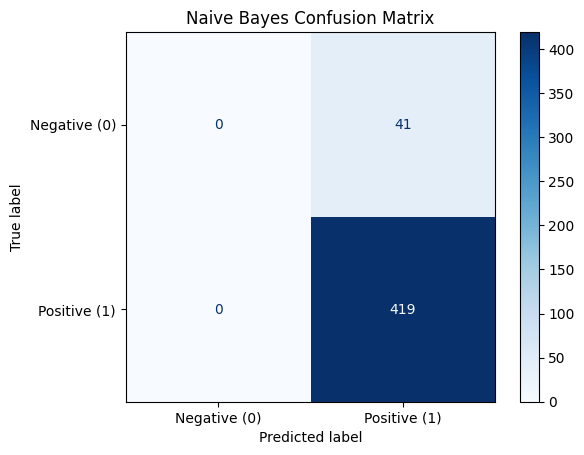

In [18]:
#Confusion Matrix
cm = confusion_matrix(
    y_test,
    mnb_predictions,
    labels=[0, 1]
)

#Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative (0)", "Positive (1)"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Naive Bayes Confusion Matrix")
plt.show()

I also created a confusion matrix to compare the actual feedback with the Naive Bayes model's predictions.The diagonal values represent correct predictions, while the other values show where the model made mistakes. This allows me to see whether the model is confusing positive and negative reviews. I thought this was helpful because even when a model has good overall accuracy, the confusion matrix can reveal areas where it still struggles.

In [19]:
#Compare the two models
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, mnb_predictions)
    ],
    "Weighted Precision": [
        precision_score(
            y_test, logistic_predictions,
            average="weighted", zero_division=0
        ),
        precision_score(
            y_test, mnb_predictions,
            average="weighted", zero_division=0
        )
    ],
    "Weighted Recall": [
        recall_score(
            y_test, logistic_predictions,
            average="weighted", zero_division=0
        ),
        recall_score(
            y_test, mnb_predictions,
            average="weighted", zero_division=0
        )
    ],
    "Weighted F1": [
        f1_score(
            y_test, logistic_predictions,
            average="weighted", zero_division=0
        ),
        f1_score(
            y_test, mnb_predictions,
            average="weighted", zero_division=0
        )
    ]
})

display(comparison.round(4))

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression,0.8891,0.9046,0.8891,0.8958
1,Multinomial Naive Bayes,0.9109,0.8297,0.9109,0.8684


I compared Logistic Regression and Multinomial Naive Bayes using the same testing dataset. I looked at their accuracy, weighted precision, weighted recall, and weighted F1 scores. Comparing the models allowed me to see whether one approach performed better at predicting feedback. I also learned that accuracy isn't the only important measurement, especially when the dataset contains more positive reviews than negative ones.

In [20]:
#Final Model Findings
print("FINAL MODEL FINDINGS")

# Logistic Regression
print("\nLogistic Regression:")
print(f"Accuracy: {accuracy_score(y_test, logistic_predictions):.4f}")
print(f"Precision: {precision_score(y_test, logistic_predictions, average='weighted', zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, logistic_predictions, average='weighted', zero_division=0):.4f}")
print(f"F1 Score: {f1_score(y_test, logistic_predictions, average='weighted', zero_division=0):.4f}")

#Multinomial Naive Bayes
print("\nMultinomial Naive Bayes:")
print(f"Accuracy: {accuracy_score(y_test, mnb_predictions):.4f}")
print(f"Precision: {precision_score(y_test, mnb_predictions, average='weighted', zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, mnb_predictions, average='weighted', zero_division=0):.4f}")
print(f"F1 Score: {f1_score(y_test, mnb_predictions, average='weighted', zero_division=0):.4f}")

#Compare model accuracy
lr_accuracy = accuracy_score(y_test, logistic_predictions)
mnb_accuracy = accuracy_score(y_test, mnb_predictions)

print("\nMODEL COMPARISON")

if lr_accuracy > mnb_accuracy:
    print("Logistic Regression had higher accuracy.")
elif mnb_accuracy > lr_accuracy:
    print("Multinomial Naive Bayes had higher accuracy.")
else:
    print("Both models had the same accuracy.")

#Custom data review prediction
print("\nCUSTOM NEGATIVE REVIEW TEST")
print("Review:", new_review[0])
print("Predicted Feedback:", int(new_prediction[0]))
print("Predicted Sentiment:",
      "Positive" if new_prediction[0] == 1 else "Negative")

FINAL MODEL FINDINGS

Logistic Regression:
Accuracy: 0.8891
Precision: 0.9046
Recall: 0.8891
F1 Score: 0.8958

Multinomial Naive Bayes:
Accuracy: 0.9109
Precision: 0.8297
Recall: 0.9109
F1 Score: 0.8684

MODEL COMPARISON
Multinomial Naive Bayes had higher accuracy.

CUSTOM NEGATIVE REVIEW TEST
Review: I am really disappointed with my Alexa. It constantly disconnects from WiFi and never understands my commands. I would not recommend it.
Predicted Feedback: 0
Predicted Sentiment: Negative
